## Homework 2

> [!NOTE]
> This homework uses the pinned 2026 car fuel-efficiency release in the course
> repository. The plan and report are available in `cohorts/2026/data/`.

### Dataset

For this homework, we'll use the 2026 Car Fuel Efficiency dataset. Download it from <a href='https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'>here</a>.

You can do it with wget:
```bash
wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
```

The goal of this homework is to create a regression model for predicting the car fuel efficiency (column `'fuel_efficiency_mpg'`).

### Preparing the dataset 

Use only the following columns:

* `'engine_displacement'`,
* `'horsepower'`,
* `'vehicle_weight'`,
* `'model_year'`,
* `'fuel_efficiency_mpg'`

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv(
    '../assets/car_fuel_efficiency_2026.csv',
    usecols=[
        'engine_displacement',
        'horsepower',
        'vehicle_weight',
        'model_year',
        'fuel_efficiency_mpg',
    ],
)

df.head()

TARGET_VAR = 'fuel_efficiency_mpg'

,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
0,2006,2180,243.0,3870,31.9
1,2008,2390,272.0,4210,31.3
2,1996,2320,267.0,4240,27.5
3,1989,2130,258.0,4490,28.5
4,1994,2580,304.0,4510,31.0


### EDA

* Look at the `fuel_efficiency_mpg` variable. Does it have a long tail?

<Axes: >

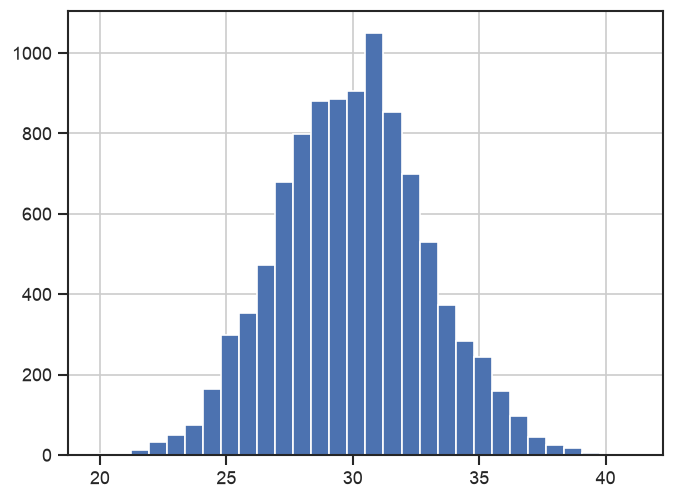

In [3]:
df['fuel_efficiency_mpg'].hist(bins=30)

### Question 1

There's one column with missing values. What is it?

* `'engine_displacement'` 
* `'horsepower'` ✅ 
* `'vehicle_weight'`
* `'model_year'`

In [4]:
df.isna().sum().loc[lambda x: x > 0]

horsepower    877
Length: 1, dtype: int64

### Question 2

What's the median (50% percentile) for variable `'horsepower'`?

- 204
- 254 ✅ 
- 304
- 354

In [5]:
df['horsepower'].median()

np.float64(254.0)

### Prepare and split the dataset

Shuffle the filtered dataset and create the split exactly as in the lecture:

```python
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]
```

For Q5, repeat the same block with each listed seed. For Q6, use seed `9`.

In [6]:
def split_train_val_test(df, seed=42):
    n = len(df)
    n_val = n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)

    return (
        df.iloc[idx[:n_train]],
        df.iloc[idx[n_train : n_train + n_val]],
        df.iloc[idx[n_train + n_val :]],
    )


df_train, df_val, df_test = split_train_val_test(df)


### Question 3

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 3 decimal digits using `round(score, 3)`. This
  keeps the imputation difference visible in this release.
* Which option gives better RMSE?

Options:

- With 0  
- With mean ✅ 
- Both are equally good

In [7]:
def prepare_X_y(df, fill_value):
    df_filled = df.fillna(fill_value)
    return (
        df_filled.drop(columns=TARGET_VAR).astype(np.float64).to_numpy(),
        df_filled[TARGET_VAR].astype(np.float64).to_numpy(),
    )


def train_linear_regression(X, y, alpha):
    X = np.column_stack([np.ones(X.shape[0]), X])
    XTX_reg = X.T @ X + alpha * np.identity(X.shape[1])
    return np.linalg.inv(XTX_reg) @ X.T @ y


def predict_y(w, X):
    return w[0] + X @ w[1:]


def calulate_rmse(y_pred, y_true):
    return np.sqrt(((y_pred - y_true) ** 2).mean())


def linear_reg_rmse(df_train, df_val, fill_value: float | pd.Series = 0, alpha: float = 0):
    """linear regression process including training and validation.
    Return RMSE of validation dataset"""
    X_train, y_train = prepare_X_y(df_train, fill_value=fill_value)
    X_val, y_val = prepare_X_y(df_val, fill_value=fill_value)

    w = train_linear_regression(X_train, y_train, alpha=alpha)
    y_val_pred = predict_y(w, X_val)

    return calulate_rmse(y_val_pred, y_val)


round(linear_reg_rmse(df_train, df_val, fill_value=0), 3)
round(linear_reg_rmse(df_train, df_val, fill_value=df_train.mean()), 3)


np.float64(2.205)

np.float64(2.202)

### Question 4

* Now let's train a regularized linear regression.
* For this question, fill the NAs with 0. 
* Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
* Use RMSE to evaluate the model on the validation dataset.
* Round the RMSE scores to 4 decimal digits. This keeps the small but real
  regularization differences visible instead of turning several choices into a tie.
* Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0 ✅ 
- 0.01 
- 0.1
- 1
- 5
- 10
- 100

In [8]:
results = []
for alpha in [0, 0.01, 0.1, 1, 5, 10, 100]:
    rmse = linear_reg_rmse(df_train, df_val, alpha=alpha)
    results.append((alpha, round(rmse, 4)))

for alpha, rmse in sorted(results, key=lambda x: x[1]):
    print(f'alpha: {alpha:5}\trmse: {rmse}')


alpha:     0	rmse: 2.2053
alpha:  0.01	rmse: 2.2058
alpha:   0.1	rmse: 2.2241
alpha:     1	rmse: 2.3492
alpha:     5	rmse: 2.4094
alpha:    10	rmse: 2.4195
alpha:   100	rmse: 2.4292


### Question 5 

* We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
* Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
* For each seed, do the train/validation/test split with 60%/20%/20% distribution.
* Fill the missing values with 0 and train a model without regularization.
* For each seed, evaluate the model on the validation dataset and collect the RMSE scores. 
* What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
* Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?

- 0.006
- 0.016
- 0.029 ✅ 
- 0.036

> Note: Standard deviation shows how different the values are.
> If it's low, then all values are approximately the same.
> If it's high, the values are different. 
> If standard deviation of scores is low, then our model is *stable*.

In [9]:
rmses = []
for seed in range(10):
    df_train, df_val, df_test = split_train_val_test(df, seed)
    rmse = linear_reg_rmse(df_train, df_val)
    rmses.append(rmse)
    print(f'seed: {seed} \trmse: {round(rmse, 4)}')

np.std(rmses).round(3)


seed: 0 	rmse: 2.2392
seed: 1 	rmse: 2.2021
seed: 2 	rmse: 2.1634
seed: 3 	rmse: 2.2044
seed: 4 	rmse: 2.2019
seed: 5 	rmse: 2.2458
seed: 6 	rmse: 2.2697
seed: 7 	rmse: 2.1908
seed: 8 	rmse: 2.2166
seed: 9 	rmse: 2.207


np.float64(0.029)

### Question 6

* Split the dataset like previously, use seed 9.
* Combine train and validation datasets.
* Fill the missing values with 0 and train a model with `r=0.001`. 
* What's the RMSE on the test dataset?

Options:

- 0.236
- 2.236 ✅ 
- 22.10
- 221.0

In [10]:
df_train, df_val, df_test = split_train_val_test(df, seed=9)
linear_reg_rmse(pd.concat((df_train, df_val)), df_test, alpha=0.001).round(3)


np.float64(2.236)